Cel zadania to zbudowanie modelu przewidujacego czy dany samochod ma wysokie spalanie czy niskie na galonie paliwa.

In [30]:
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
from sklearn.base import clone
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Podpunkt A  

crim - wskaźnik przestępczości 

* 0 - niski wskażnik przestepstw
* 1 - wysoki wskaźnik przestepstw

In [31]:
Boston = pd.read_csv('data/Boston.csv',index_col=0)
Boston.info()
Boston['high_crime_rate'] = (Boston['crim'] > Boston['crim'].median()).map({
    True: 'wysoka',
    False: 'niska'
})
display(Boston)

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 1 to 506
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  lstat    506 non-null    float64
 12  medv     506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv,high_crime_rate
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0,niska
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6,niska
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7,niska
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4,niska
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2,niska
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
502,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4,niska
503,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6,niska
504,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9,niska
505,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0,niska


# Podpunkt B

* zn – odsetek gruntów mieszkalnych przeznaczonych pod zabudowę z dużymi działkami (> 25 000 sq. ft.)
* indus – odsetek powierzchni zajmowanej przez firmy niehandlowe
* chas – zmienna binarna: czy obszar graniczy z rzeką Charles (1 = tak, 0 = nie)
* nox – stężenie tlenków azotu (w częściach na 10 mln)
* rm – średnia liczba pokoi na mieszkanie
* age – odsetek lokali wybudowanych przed 1940 rokiem
* dis – ważona odległość do 5 głównych ośrodków zatrudnienia w Bostonie
* rad – indeks dostępności do radialnych dróg szybkiego ruchu
* tax – pełna stawka podatku od nieruchomości na 10 000 USD wartości
* ptratio – stosunek liczby uczniów do liczby nauczycieli w szkołach
* lstat – odsetek mieszkańców o niższym statusie społeczno-ekonomicznym
* medv – mediana wartości mieszkań zamieszkanych przez właścicieli (w tys. USD)
* high_crime_rate – zmienna docelowa: 1 dla wskaźnika przestępczości (crim) powyżej mediany, 0 w przeciwnym razie

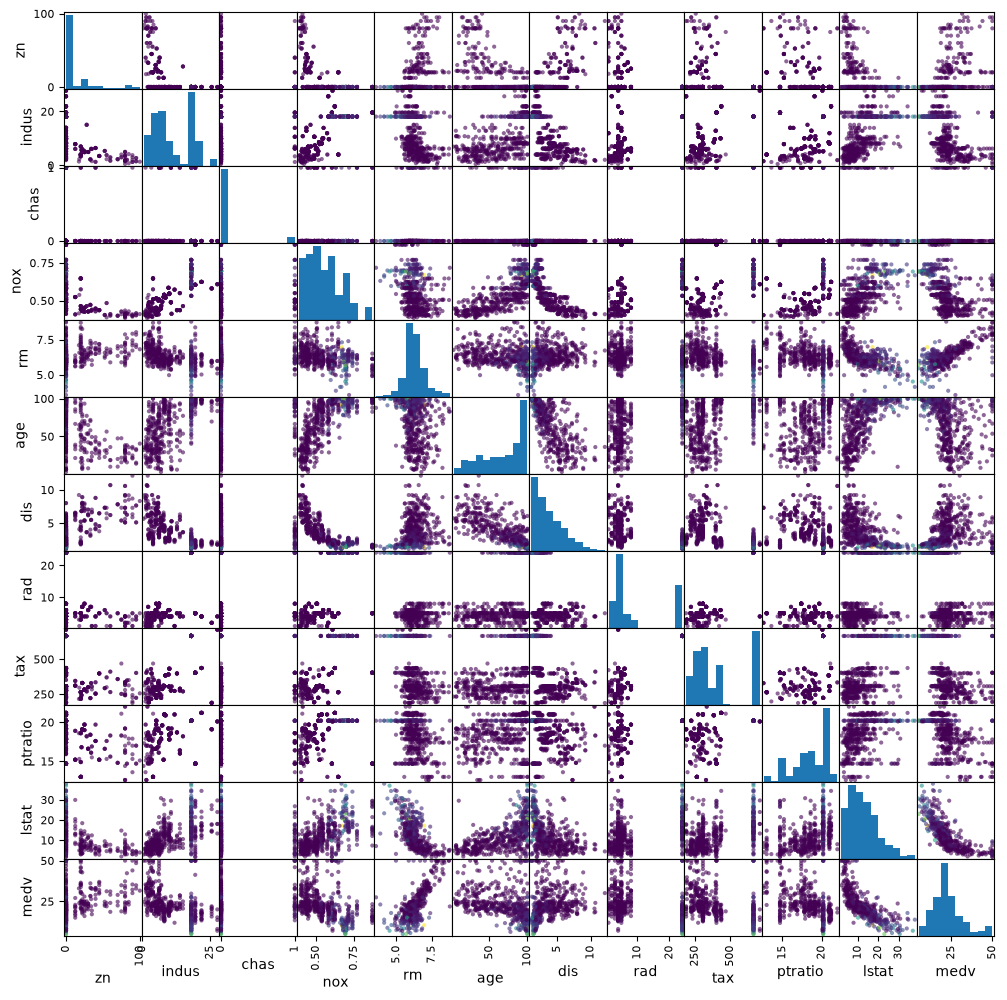

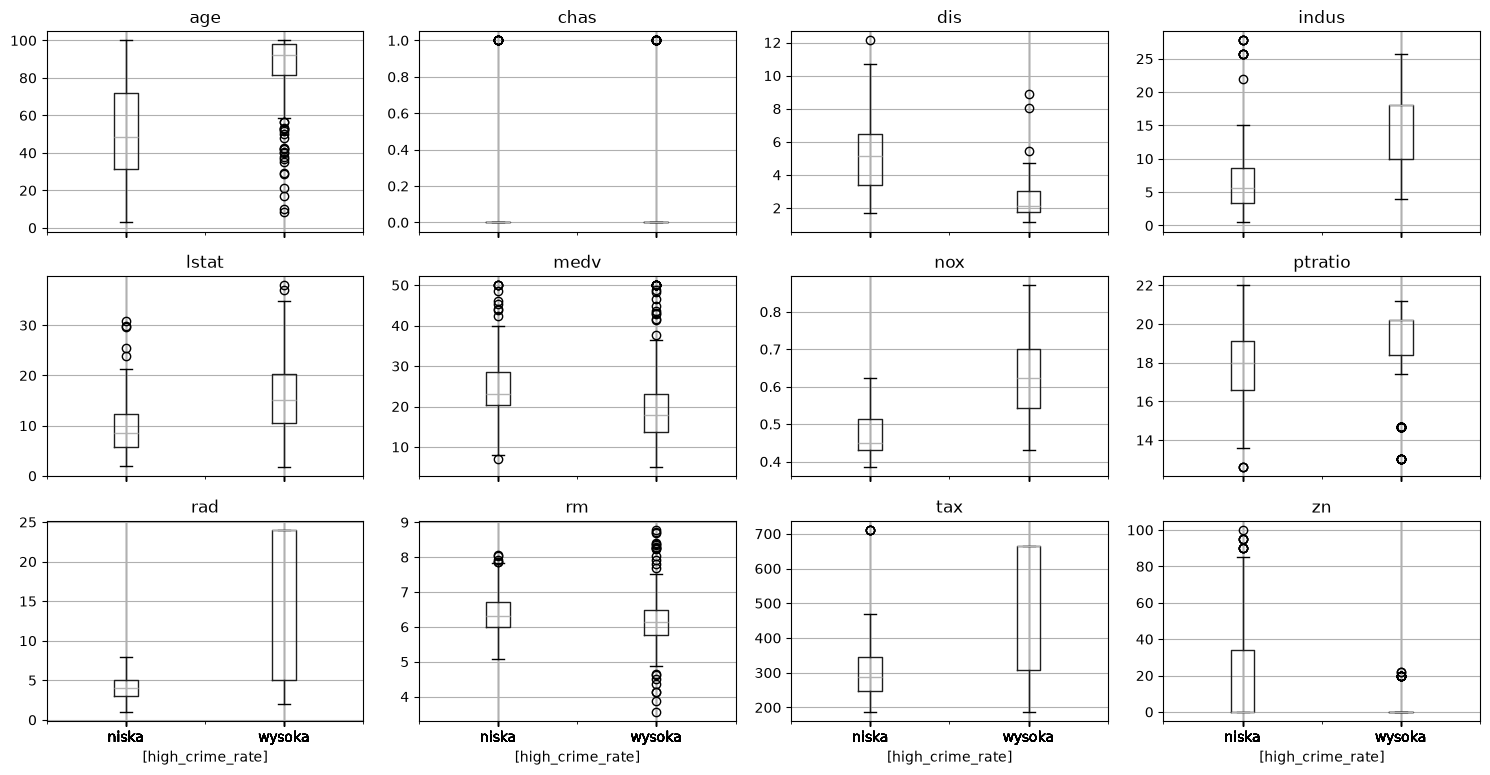

In [32]:
cechy = Boston.drop(columns=['crim','high_crime_rate'])
pd.plotting.scatter_matrix(cechy,c=Boston['crim'],diagonal='hist',figsize=(12,12),alpha=0.6)
Boston.drop(columns=['crim']).boxplot(by='high_crime_rate', figsize=(15, 8), layout=(3, 4),sharey=False)
plt.suptitle('')
plt.tight_layout()
plt.show()

# Podpunkt C

zbior testowy - 80%, zbior treningowy - 20%

              dis       nox     indus     lstat       tax      medv        zn  \
dis      1.000000 -0.778379 -0.711618 -0.515004 -0.538617  0.265096  0.654789   
nox     -0.778379  1.000000  0.761496  0.604058  0.675743 -0.437443 -0.514982   
indus   -0.711618  0.761496  1.000000  0.621343  0.723553 -0.496165 -0.529102   
lstat   -0.515004  0.604058  0.621343  1.000000  0.540566 -0.731135 -0.402975   
tax     -0.538617  0.675743  0.723553  0.540566  1.000000 -0.471642 -0.311133   
medv     0.265096 -0.437443 -0.496165 -0.731135 -0.471642  1.000000  0.353003   
zn       0.654789 -0.514982 -0.529102 -0.402975 -0.311133  0.353003  1.000000   
ptratio -0.244576  0.207088  0.400700  0.370979  0.465887 -0.491470 -0.402399   
rad     -0.503752  0.626194  0.599659  0.480399  0.906014 -0.378828 -0.310899   

          ptratio       rad  
dis     -0.244576 -0.503752  
nox      0.207088  0.626194  
indus    0.400700  0.599659  
lstat    0.370979  0.480399  
tax      0.465887  0.906014  
medv    -

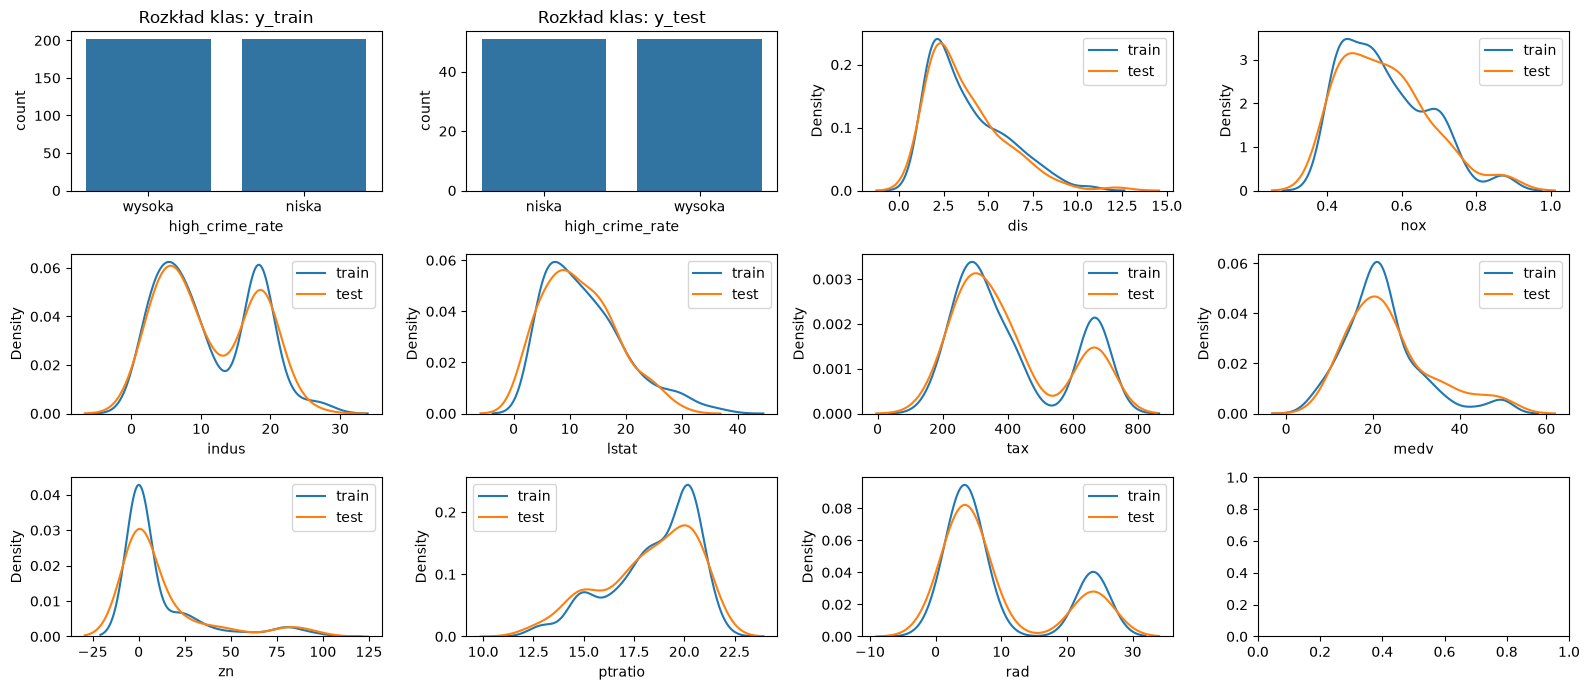

              dis         nox       indus       lstat         tax        medv  \
count  404.000000  404.000000  404.000000  404.000000  404.000000  404.000000   
mean     3.816735    0.554532   11.139777   12.865842  410.584158   22.156436   
std      2.120652    0.115466    6.907098    7.304044  170.590073    8.941527   
min      1.129600    0.385000    0.460000    2.870000  188.000000    5.000000   
25%      2.077100    0.453000    5.175000    6.990000  280.750000   16.800000   
50%      3.267450    0.538000    9.690000   11.465000  330.000000   21.000000   
75%      5.287300    0.631000   18.100000   17.127500  666.000000   24.800000   
max     10.710300    0.871000   27.740000   37.970000  711.000000   50.000000   

               zn     ptratio         rad  
count  404.000000  404.000000  404.000000  
mean    11.128713   18.507673    9.668317  
std     23.012231    2.130463    8.779566  
min      0.000000   12.600000    1.000000  
25%      0.000000   17.400000    4.000000  
50%   

In [33]:
X = Boston[['dis','nox','indus','lstat','tax','medv','zn','ptratio','rad']]
Y = Boston['high_crime_rate']
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=30,stratify=Y)
print(x_train.corr())
fig, axes = plt.subplots(3, 4, figsize=(16, 7))
axes = axes.flatten()

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title('Rozkład klas: y_train')

sns.countplot(x=y_test, ax=axes[1])
axes[1].set_title('Rozkład klas: y_test')


for i,kol in enumerate(X.columns,start=2):
    sns.kdeplot(x_train[kol],label='train',ax=axes[i])
    sns.kdeplot(x_test[kol],label='test',ax=axes[i])
    axes[i].legend()


plt.tight_layout()
plt.show()
print(x_train.describe())
print(x_test.describe())


# Podpunkt D,E,F,G,H

In [45]:
clfs = {
    "LDA":Pipeline([('method',LinearDiscriminantAnalysis())
    ]),
    "QDA":Pipeline([('method',QuadraticDiscriminantAnalysis())             
    ]),
    "KNN":Pipeline([('Standard_scaler',StandardScaler()), 
        ('method',KNeighborsClassifier(n_neighbors=7))
    ]),
    "LG":Pipeline([('Standard_scaler',StandardScaler()), 
        ('method',LogisticRegression(max_iter=1000))
    ]),
    "Naive_Bayes":Pipeline([('Standard_scaler',StandardScaler()),
        ('method',GaussianNB())
    ]) 
      
}

In [46]:
predykcje = {}
for (nazwa,clf) in clfs.items(): 
    clf.fit(x_train,y_train)
    predykcje[nazwa] = clf.predict(x_test)
    acc = accuracy_score(y_test, predykcje[nazwa])
    print(f"{nazwa}: błąd testowy = {1 - acc:.4f}, accuracy = {acc:.4f}")
    clfs[nazwa] = clone(clf)

print("\n")

cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=20)
for (nazwa,clf) in clfs.items(): 
    wyniki = cross_val_score(clf, X, Y,cv=cv, scoring='accuracy')
    print(f"{nazwa}: accuracy = {wyniki.mean():.3f} ± {wyniki.std():.3f}")



LDA: błąd testowy = 0.1275, accuracy = 0.8725
QDA: błąd testowy = 0.0196, accuracy = 0.9804
KNN: błąd testowy = 0.0392, accuracy = 0.9608
LG: błąd testowy = 0.0784, accuracy = 0.9216
Naive_Bayes: błąd testowy = 0.2059, accuracy = 0.7941


LDA: accuracy = 0.848 ± 0.051
QDA: accuracy = 0.951 ± 0.033
KNN: accuracy = 0.949 ± 0.032
LG: accuracy = 0.876 ± 0.051
Naive_Bayes: accuracy = 0.803 ± 0.052
